# Cross-validation diagram (image only, key only)

Top: the 1,462-frame video as 49 blocks of 30 frames, each numbered by its fold.
Below: for each fold, which frames are train / validation / test / buffer (15 frames either side of test).
Uses the real fold assignment. Set `THEME` to `'light'` or `'dark'`.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

THEME = 'light'
SAVE = True
DPI = 150
SHOW_FOLD_LABELS = True     # 'Fold 1'...'Fold 5' row labels on the left

In [2]:
BLOCK_FOLD = [3, 1, 2, 2, 4, 3, 0, 1, 3, 3, 1, 1, 2, 3, 3, 2, 0, 1, 0, 0, 4, 0, 1, 3, 0, 4, 2, 1, 1, 3, 1, 0, 4, 3,
              3, 4, 0, 4, 2, 4, 4, 2, 1, 0, 2, 2, 0, 2, 4]          # fold (0-based) of each 30-frame block
FRAMES = np.arange(1000, 2462); BLOCK = (FRAMES - 1000) // 30; NB = len(BLOCK_FOLD); BUFFER = 15
FOLD_OF = np.array([BLOCK_FOLD[b] for b in BLOCK])

In [3]:
THEMES = {
    'light': dict(bg='#ffffff', ink='#0b0b0b', ink2='#52514e', card='#f4f3ef', line='#c9c8c1', base='#a3a29b',
                  blue='#2a78d6', orange='#eb6834', violet='#6250d6'),
    'dark':  dict(bg='#0f1b2d', ink='#f0efec', ink2='#c3c2b7', card='#18283f', line='#3a4a62', base='#7f8a9b',
                  blue='#4a90e8', orange='#e2683a', violet='#9085e9'),
}
T = THEMES[THEME]
plt.rcParams.update({'font.family': 'DejaVu Sans', 'figure.facecolor': T['bg'], 'savefig.facecolor': T['bg']})

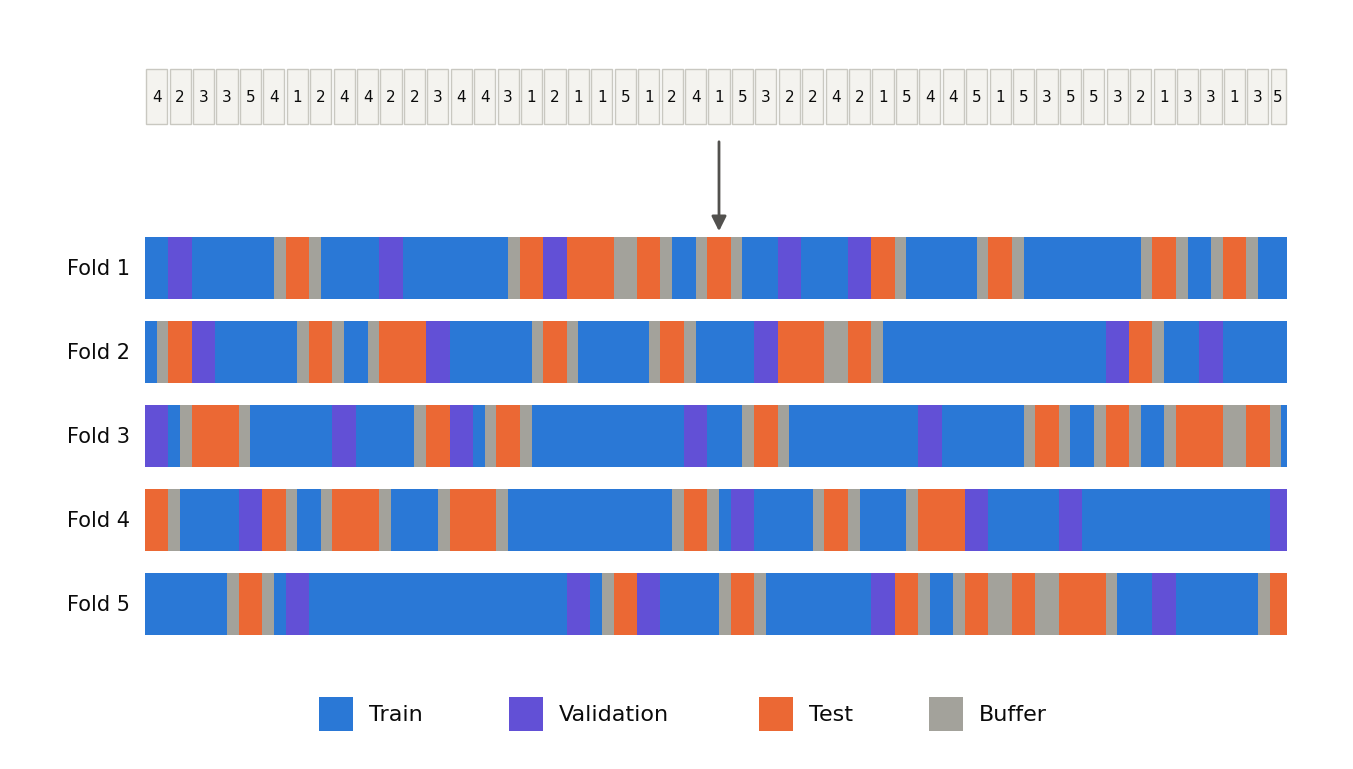

In [4]:
fig = plt.figure(figsize=(13.33, 7.5)); ax = fig.add_axes([0, 0, 1, 1]); ax.set_xlim(0, 13.33); ax.set_ylim(0, 7.5); ax.axis('off')
X0 = 1.35 if SHOW_FOLD_LABELS else 0.5; X1 = 12.83; bw = (X1 - X0) / NB
fx = lambda f: X0 + (f - 1000) / 30 * bw
col = {'train': T['blue'], 'val': T['violet'], 'test': T['orange'], 'buffer': T['base']}

# top strip: blocks numbered by fold
yt = 6.35
for b in range(NB):
    w = bw * (22 / 30 if b == NB - 1 else 1)
    ax.add_patch(Rectangle((X0 + b * bw + 0.012, yt), w - 0.024, 0.55, fc=T['card'], ec=T['line'], lw=1))
    ax.text(X0 + b * bw + w / 2, yt + 0.275, str(BLOCK_FOLD[b] + 1), ha='center', va='center', fontsize=11, color=T['ink'])

# arrow
ax.annotate('', ((X0 + X1) / 2, 5.25), ((X0 + X1) / 2, 6.2),
            arrowprops=dict(arrowstyle='-|>', color=T['ink2'], lw=2, mutation_scale=22))

# one row per fold
y = 4.6; rh = 0.62; gap = 0.22
for k in range(5):
    nxt = sorted(b for b in range(NB) if BLOCK_FOLD[b] == (k + 1) % 5); val = set(nxt[::2])
    test = FRAMES[FOLD_OF == k]
    role = ['test' if FOLD_OF[i] == k else 'val' if BLOCK[i] in val else
            'buffer' if np.min(np.abs(test - f)) <= BUFFER else 'train' for i, f in enumerate(FRAMES)]
    s = 0
    for i in range(1, len(FRAMES) + 1):
        if i == len(FRAMES) or role[i] != role[s]:
            ax.add_patch(Rectangle((fx(FRAMES[s]), y), fx(FRAMES[i - 1] + 1) - fx(FRAMES[s]), rh, color=col[role[s]], lw=0))
            s = i
    if SHOW_FOLD_LABELS:
        ax.text(X0 - 0.15, y + rh / 2, f'Fold {k + 1}', ha='right', va='center', fontsize=15, color=T['ink'])
    y -= rh + gap

# key
items = [('train', 'Train'), ('val', 'Validation'), ('test', 'Test'), ('buffer', 'Buffer')]
widths = [1.9, 2.5, 1.7, 1.9]; lx = X0 + ((X1 - X0) - sum(widths)) / 2; ky = 0.45
for (key, name), w in zip(items, widths):
    ax.add_patch(Rectangle((lx, ky - 0.17), 0.34, 0.34, color=col[key], lw=0))
    ax.text(lx + 0.5, ky, name, fontsize=16, color=T['ink'], va='center')
    lx += w
if SAVE:
    for ext in ('png', 'pdf'): fig.savefig(f'cv_simple_{THEME}.{ext}', dpi=DPI)
plt.show()